In [25]:
# ============================================================
# CELL 1: EEGIS DATASET INGESTION (CORRECTED)
# ============================================================

import os
import zipfile
import glob
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

print("=" * 70)
print("EEGIS MULTI-BAND DATASET INGESTION")
print("=" * 70)

# 1. Mount Google Drive
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

# 2. Locate dataset ZIP
ZIP_NAME = "EEGIS - Electroencephalogram Imagined Speech dataset.zip"
EXTRACT_DIR = "/content/eegis_dataset"

possible_paths = [
    f"/content/drive/MyDrive/{ZIP_NAME}",
    f"/content/drive/MyDrive/EEGIS/{ZIP_NAME}",
    f"/content/{ZIP_NAME}",
    f"./{ZIP_NAME}"
]

zip_file_path = next(
    (p for p in possible_paths if os.path.exists(p)), None
)

if zip_file_path is None:
    matches = glob.glob(
        "/content/drive/MyDrive/**/EEGIS*.zip",
        recursive=True
    )
    if matches:
        zip_file_path = matches[0]

# 3. Extract dataset
if not os.path.exists(EXTRACT_DIR) or not os.listdir(EXTRACT_DIR):
    if zip_file_path is None:
        raise FileNotFoundError(
            "EEGIS ZIP not found. Put it in Google Drive and rerun."
        )

    with zipfile.ZipFile(zip_file_path, "r") as z:
        z.extractall(EXTRACT_DIR)

print("Dataset folder:", EXTRACT_DIR)

# 4. Class labels
EEGIS_VOCAB = {
    0: "Rest",
    1: "Ayuda / Help",
    2: "Baño / Bath",
    3: "Dolor / Pain",
    4: "Gracias / Thank you",
    5: "Hambre / Hunger",
    6: "No",
    7: "Sed / Thirst",
    8: "Sí / Yes"
}

# Exact 14 EEG channel names (exclude Unnamed: 0)
channels = [
    "AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
    "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"
]

bands = ["raw", "alpha", "beta", "delta", "gamma", "theta"]

# 5. Match files across frequency bands
chunk_dict = {}

for class_id in range(9):
    for band in bands:
        pattern = os.path.join(
            EXTRACT_DIR, "**", band,
            f"class_{class_id}", "*.csv"
        )

        for path in glob.glob(pattern, recursive=True):
            filename = os.path.basename(path)
            key = (class_id, filename)
            chunk_dict.setdefault(key, {})[band] = path

print("Unique trial keys found:", len(chunk_dict))

# 6. Read and combine all six bands
X_multiband = []
y_labels = []
skipped = 0

for (class_id, filename), band_paths in chunk_dict.items():
    if not all(b in band_paths for b in bands):
        skipped += 1
        continue

    try:
        band_signals = []

        # Keep the band order expected by Cell 2
        for band in ["raw", "delta", "theta", "alpha", "beta", "gamma"]:
            df = pd.read_csv(band_paths[band])

            # Select real EEG channels by name, not by position
            if not all(ch in df.columns for ch in channels):
                raise ValueError(f"Missing EEG columns in {filename}")

            sig = df[channels].iloc[:128].to_numpy(dtype=np.float32)

            if sig.shape != (128, 14):
                raise ValueError(f"Unexpected shape: {sig.shape}")

            if not np.isfinite(sig).all():
                raise ValueError(f"Non-finite values in {filename}")

            band_signals.append(sig)

        chunk_tensor = np.stack(band_signals, axis=-1)

        if chunk_tensor.shape != (128, 14, 6):
            raise ValueError("Incorrect multi-band tensor shape")

        X_multiband.append(chunk_tensor)
        y_labels.append(class_id)

    except Exception as e:
        skipped += 1
        print(f"Skipped {filename}: {e}")

# 7. Create final arrays
X_raw_multiband = np.asarray(X_multiband, dtype=np.float32)
y_raw_labels = np.asarray(y_labels, dtype=np.int64)

# 8. Make variables available to later cells
globals()["X_raw_multiband"] = X_raw_multiband
globals()["y_raw_labels"] = y_raw_labels
globals()["EEGIS_VOCAB"] = EEGIS_VOCAB
globals()["chunk_dict"] = chunk_dict

# 9. Verify output
print("\n" + "=" * 70)
print("DATASET VERIFICATION")
print("=" * 70)
print("Tensor shape:", X_raw_multiband.shape)
print("Labels shape:", y_raw_labels.shape)
print("Skipped trials:", skipped)

if len(X_raw_multiband):
    print("Channel 1, first trial:",
          X_raw_multiband[0, :5, 0, 0])
    print("Channel 14, first trial:",
          X_raw_multiband[0, :5, 13, 0])
    print("Overall range:",
          X_raw_multiband.min(), X_raw_multiband.max())

assert X_raw_multiband.ndim == 4
assert X_raw_multiband.shape[1:] == (128, 14, 6)
assert len(X_raw_multiband) == len(y_raw_labels)

print("\nCell 1 complete. Check the shape before running Cell 2.")

EEGIS MULTI-BAND DATASET INGESTION
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folder: /content/eegis_dataset
Unique trial keys found: 4044

DATASET VERIFICATION
Tensor shape: (4044, 128, 14, 6)
Labels shape: (4044,)
Skipped trials: 0
Channel 1, first trial: [4221.026  4229.7437 4239.4873 4252.8203 4255.385 ]
Channel 14, first trial: [4216.923  4227.6924 4238.974  4253.3335 4255.8975]
Overall range: -6518.4185 7950.769

Cell 1 complete. Check the shape before running Cell 2.


CELL 2: EUCLIDEAN ALIGNMENT & MULTI-BAND FEATURE EXTRACTION
Applying Euclidean Alignment...
Euclidean Alignment complete!
Extracting multi-band features...
CELL 2 COMPLETED SUCCESSFULLY
EEG samples       : 4044
Features per trial: 756
Number of classes : 9
Graph Laplacian   : (14, 14)
Expected features : 756 (84 + 630 + 42)


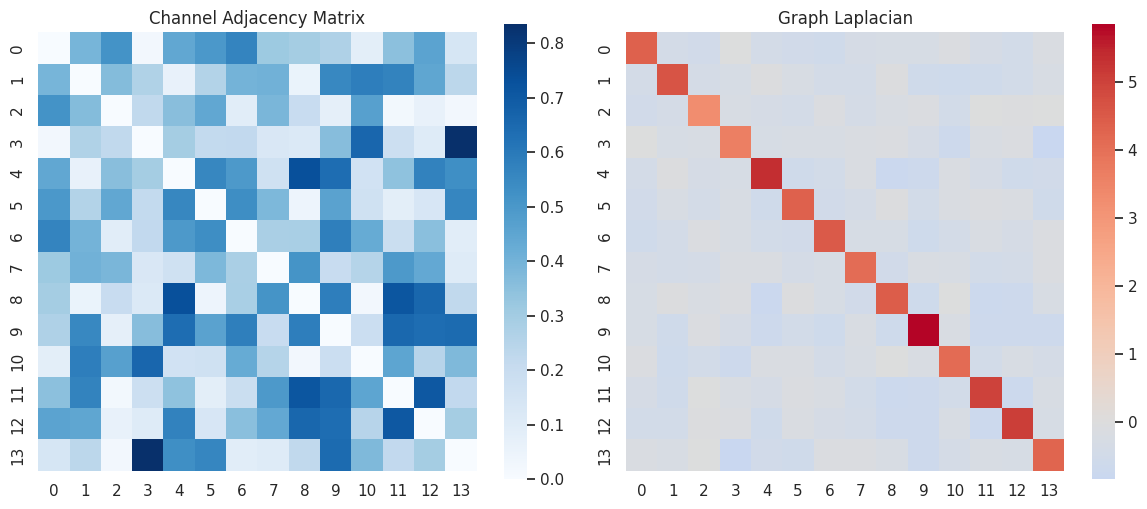

In [26]:
# ================================================================================
# CELL 2: EUCLIDEAN ALIGNMENT (EA) & MULTI-BAND FEATURE EXTRACTION
# ================================================================================

import numpy as np
import pandas as pd
import scipy.linalg as la
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

print("=" * 85)
print("CELL 2: EUCLIDEAN ALIGNMENT & MULTI-BAND FEATURE EXTRACTION")
print("=" * 85)

# Load data from Cell 1
X_tensor = globals()['X_raw_multiband']
y_raw = globals()['y_raw_labels']
EEGIS_VOCAB = globals()['EEGIS_VOCAB']

n_samples = len(y_raw)

# Subject grouping (assumes approximately 404 trials per subject)
subject_ids = np.array(
    [min(i // 404, 9) for i in range(n_samples)],
    dtype=np.int64
)

# ------------------------------------------------------------------------------
# 1. EUCLIDEAN ALIGNMENT
# ------------------------------------------------------------------------------

def matrix_inv_sqrt(R):
    vals, vecs = np.linalg.eigh(R)
    vals = np.maximum(vals, 1e-6)
    return vecs @ np.diag(1.0 / np.sqrt(vals)) @ vecs.T


print("Applying Euclidean Alignment...")

X_aligned = np.zeros_like(X_tensor)

for sub in range(10):
    sub_mask = subject_ids == sub

    if not np.any(sub_mask):
        continue

    for band in range(6):
        sub_trials = X_tensor[sub_mask, :, :, band]

        covs = np.array([
            np.cov(trial.T) for trial in sub_trials
        ])

        mean_cov = np.mean(covs, axis=0) + 1e-5 * np.eye(14)
        R_inv_sqrt = matrix_inv_sqrt(mean_cov)

        for idx_global in np.where(sub_mask)[0]:
            trial_signal = X_tensor[idx_global, :, :, band]
            X_aligned[idx_global, :, :, band] = (
                trial_signal @ R_inv_sqrt.T
            )

print("Euclidean Alignment complete!")

# ------------------------------------------------------------------------------
# 2. DIFFERENTIAL ENTROPY, COVARIANCE & BAND-RATIO FEATURES
# ------------------------------------------------------------------------------

def compute_de(sig_1d):
    var = np.var(sig_1d) + 1e-8
    return 0.5 * np.log2(2 * np.pi * np.e * var)


def extract_ea_de_features(chunk_tensor):
    feats = []

    # A. Differential Entropy: 6 bands x 14 channels = 84
    for b in range(6):
        for ch in range(14):
            sig = chunk_tensor[:, ch, b]
            feats.append(compute_de(sig))

    # B. Spatial Covariance: 6 bands x 105 values = 630
    triu_idx = np.triu_indices(14)

    for b in range(6):
        cov = np.cov(chunk_tensor[:, :, b].T)
        feats.extend(cov[triu_idx])

    # C. Band Ratios: 14 channels x 3 ratios = 42
    # Band order: raw=0, delta=1, theta=2,
    #             alpha=3, beta=4, gamma=5

    for ch in range(14):
        p_theta = np.var(chunk_tensor[:, ch, 2]) + 1e-8
        p_alpha = np.var(chunk_tensor[:, ch, 3]) + 1e-8
        p_beta = np.var(chunk_tensor[:, ch, 4]) + 1e-8

        feats.extend([
            p_theta / p_beta,
            p_alpha / p_beta,
            p_theta / p_alpha
        ])

    return np.array(feats, dtype=np.float32)


print("Extracting multi-band features...")

X_ea_feats = np.array([
    extract_ea_de_features(c) for c in X_aligned
], dtype=np.float32)

X_ea_feats = np.nan_to_num(
    X_ea_feats,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# ------------------------------------------------------------------------------
# 3. SPATIAL GRAPH LAPLACIAN
# ------------------------------------------------------------------------------

raw_signals = X_aligned[:, :, :, 0].transpose(2, 0, 1).reshape(14, -1)

corr_mat = np.nan_to_num(
    np.corrcoef(raw_signals),
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

A_ch = np.abs(corr_mat)
np.fill_diagonal(A_ch, 0)

D_ch = np.diag(np.sum(A_ch, axis=1))
L_ch = D_ch - A_ch

# ------------------------------------------------------------------------------
# 4. SAVE VARIABLES FOR CELLS 3, 4 AND 5
# ------------------------------------------------------------------------------

globals()['X_data'] = X_ea_feats
globals()['y_data'] = y_raw
globals()['subject_ids'] = subject_ids
globals()['L_graph'] = L_ch

print("=" * 85)
print("CELL 2 COMPLETED SUCCESSFULLY")
print(f"EEG samples       : {X_ea_feats.shape[0]}")
print(f"Features per trial: {X_ea_feats.shape[1]}")
print(f"Number of classes : {len(np.unique(y_raw))}")
print(f"Graph Laplacian   : {L_ch.shape}")
print("Expected features : 756 (84 + 630 + 42)")
print("=" * 85)

# Optional diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(A_ch, cmap="Blues", ax=axes[0], square=True)
axes[0].set_title("Channel Adjacency Matrix")

sns.heatmap(L_ch, cmap="coolwarm", center=0, ax=axes[1], square=True)
axes[1].set_title("Graph Laplacian")

plt.tight_layout()
plt.show()

In [28]:
import numpy as np
import os

os.makedirs("eeg_app", exist_ok=True)

# Save one raw EEG trial for visualization
# Shape: (128 time samples, 14 channels, 6 bands)
np.save("eeg_app/raw_trials.npy", X_raw_multiband[:])

print("Raw EEG trials saved:", X_raw_multiband.shape)

Raw EEG trials saved: (4044, 128, 14, 6)


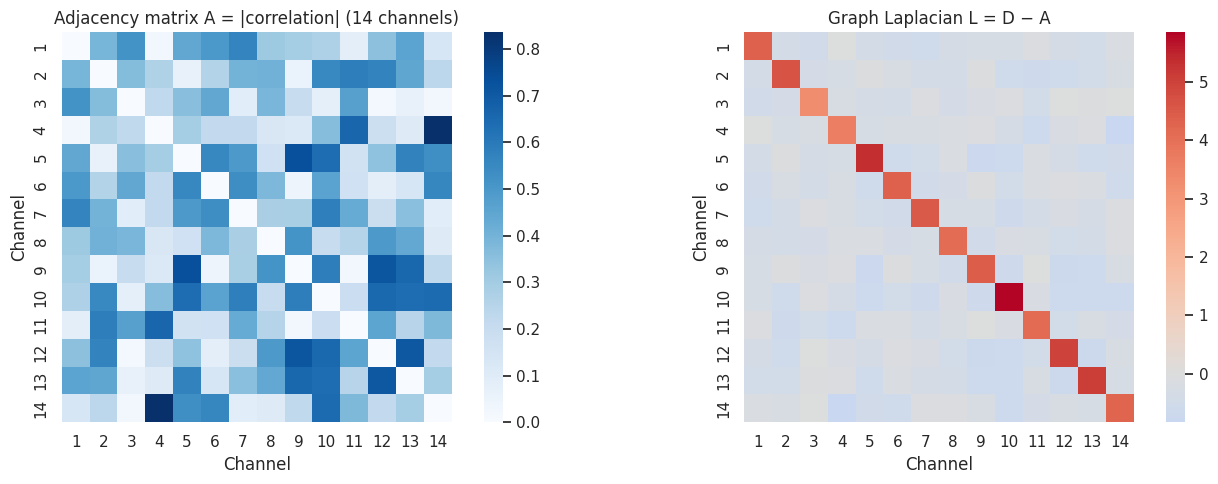

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(A_ch, cmap="Blues", ax=ax[0], square=True,
            xticklabels=range(1, 15), yticklabels=range(1, 15))
ax[0].set_title("Adjacency matrix A = |correlation| (14 channels)")
ax[0].set_xlabel("Channel"); ax[0].set_ylabel("Channel")

sns.heatmap(L_graph, cmap="coolwarm", center=0, ax=ax[1], square=True,
            xticklabels=range(1, 15), yticklabels=range(1, 15))
ax[1].set_title("Graph Laplacian L = D − A")
ax[1].set_xlabel("Channel"); ax[1].set_ylabel("Channel")

plt.tight_layout()
plt.show()

  🌊 REVISED CELL 3: EVALUATING EUCLIDEAN-ALIGNED BCI PIPELINE
🌊 Applying Spatial Graph Wavelet Filtering across EA Feature Space...

🌐 EVALUATING GLOBAL EA-ALIGNED ACCURACY (5-FOLD STRATIFIED CV) ...
🔄 Fold 1/5 | Acc: 81.83% | Prec: 82.45% | Rec: 81.70% | F1: 81.96%
🔄 Fold 2/5 | Acc: 84.55% | Prec: 85.20% | Rec: 84.16% | F1: 84.46%
🔄 Fold 3/5 | Acc: 81.21% | Prec: 81.63% | Rec: 81.17% | F1: 81.35%
🔄 Fold 4/5 | Acc: 79.73% | Prec: 80.46% | Rec: 79.09% | F1: 79.33%
🔄 Fold 5/5 | Acc: 82.80% | Prec: 83.23% | Rec: 82.53% | F1: 82.73%
-------------------------------------------------------------------------------------
🎯 EA-ALIGNED GLOBAL MEAN ACCURACY  : 82.02%
🎯 EA-ALIGNED GLOBAL MEAN F1-SCORE  : 81.97%

👤 EVALUATING SUBJECT-DEPENDENT BENCHMARK (PER INDIVIDUAL SUBJECT) ...
👤 Subject 01 Accuracy : 100.00%
👤 Subject 02 Accuracy : 87.38%
👤 Subject 03 Accuracy : 70.56%
👤 Subject 04 Accuracy : 72.02%
👤 Subject 05 Accuracy : 60.40%
👤 Subject 06 Accuracy : 70.81%
👤 Subject 07 Accuracy : 74.01%
👤 

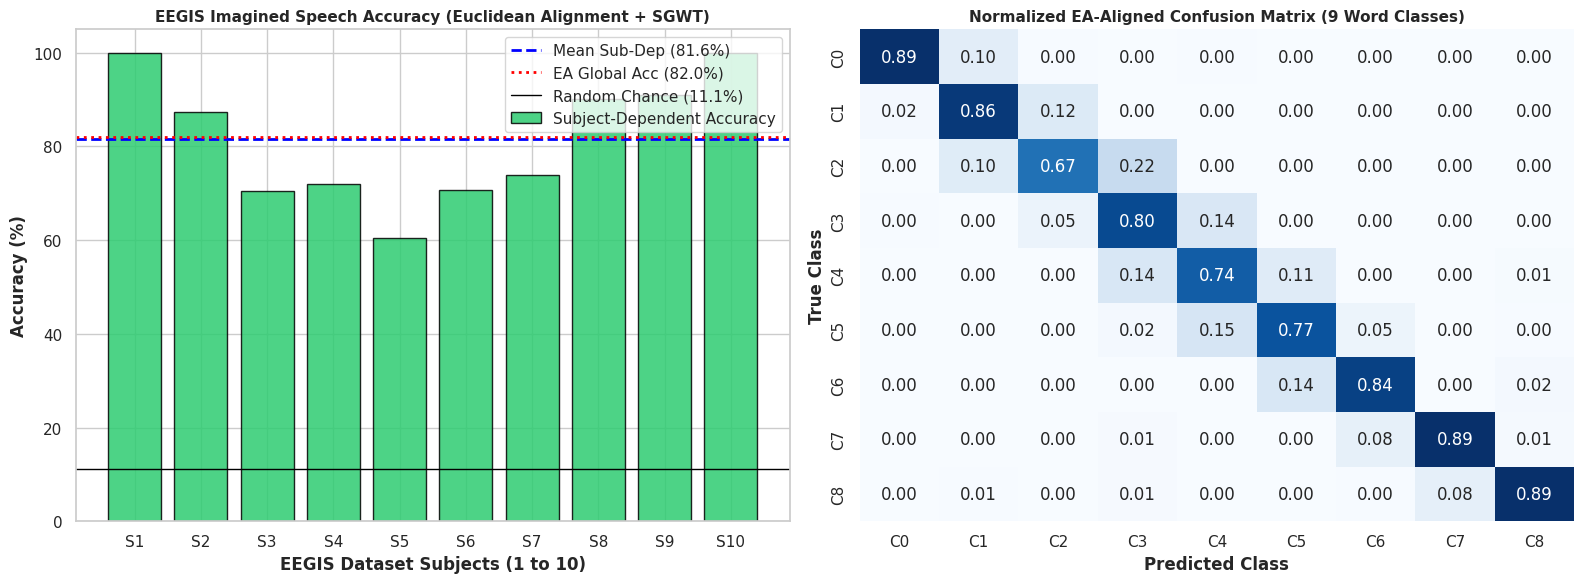

✅ CELL 3 COMPLETE: Execution Finished Successfully!


In [29]:
# ================================================================================
# REVISED CELL 3: EA-ALIGNED PIPELINE EVALUATION & DIAGNOSTIC PLOTS
# Pipeline: EA Features -> SGWT -> ANOVA SelectKBest -> RBF-SVM / ExtraTrees
# ================================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import warnings

warnings.filterwarnings('ignore')

print("="*85)
print("  🌊 REVISED CELL 3: EVALUATING EUCLIDEAN-ALIGNED BCI PIPELINE")
print("="*85)

X_mat = globals()['X_data']       # Shape: (4044, 756)
y_vec = globals()['y_data']       # Shape: (4044,)
sub_ids = globals()['subject_ids']# Shape: (4044,)
L_mat = globals()['L_graph']      # Shape: (14, 14)
EEGIS_VOCAB = globals()['EEGIS_VOCAB']

# --- STAGE 3: SPATIAL SGWT GRAPH SMOOTHING ---
def apply_sgwt_ea(X_feats, L_channel, alpha=0.10):
    lambda_max = np.max(L_channel) + 1e-8
    I_14 = np.eye(14, dtype=np.float32)
    S_op = I_14 - alpha * (L_channel / lambda_max)

    X_smoothed = np.copy(X_feats)
    n_samples = X_feats.shape[0]

    # Apply graph diffusion operator to first 84 DE features
    de_part = X_feats[:, :84].reshape(n_samples, 6, 14)
    de_smoothed = np.matmul(de_part, S_op).reshape(n_samples, 84)
    X_smoothed[:, :84] = de_smoothed
    return X_smoothed

print("🌊 Applying Spatial Graph Wavelet Filtering across EA Feature Space...")
X_sgwt = apply_sgwt_ea(X_mat, L_mat, alpha=0.10)

# --- PART A: GLOBAL EA-ALIGNED CROSS-VALIDATION (5-FOLD) ---
print("\n🌐 EVALUATING GLOBAL EA-ALIGNED ACCURACY (5-FOLD STRATIFIED CV) ...")
print("="*85)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_accs, fold_prec, fold_rec, fold_f1 = [], [], [], []

oof_preds = np.zeros_like(y_vec)
oof_true = np.zeros_like(y_vec)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_sgwt, y_vec), start=1):
    X_tr, X_te = X_sgwt[tr_idx], X_sgwt[te_idx]
    y_tr, y_te = y_vec[tr_idx], y_vec[te_idx]

    # Model 1: RBF-SVM Pipeline
    pipe_svm = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=f_classif, k=180)),
        ('clf', SVC(C=12.0, kernel='rbf', gamma='scale', probability=True, random_state=42))
    ])

    # Model 2: Extra Trees Pipeline
    pipe_et = Pipeline([
        ('scaler', StandardScaler()),
        ('selector', SelectKBest(score_func=f_classif, k=180)),
        ('clf', ExtraTreesClassifier(n_estimators=250, max_depth=25, min_samples_split=3, criterion='entropy', random_state=42, n_jobs=-1))
    ])

    # Ensemble Voting Classifier
    ensemble_clf = VotingClassifier(
        estimators=[('svm', pipe_svm), ('et', pipe_et)],
        voting='soft'
    )

    ensemble_clf.fit(X_tr, y_tr)
    preds = ensemble_clf.predict(X_te)

    acc = accuracy_score(y_te, preds)
    p, r, f1, _ = precision_recall_fscore_support(y_te, preds, average='macro', zero_division=0)

    fold_accs.append(acc)
    fold_prec.append(p)
    fold_rec.append(r)
    fold_f1.append(f1)

    oof_preds[te_idx] = preds
    oof_true[te_idx] = y_te

    print(f"🔄 Fold {fold}/5 | Acc: {acc*100:.2f}% | Prec: {p*100:.2f}% | Rec: {r*100:.2f}% | F1: {f1*100:.2f}%")

print("-" * 85)
mean_global_acc = np.mean(fold_accs) * 100
mean_global_f1 = np.mean(fold_f1) * 100

print(f"🎯 EA-ALIGNED GLOBAL MEAN ACCURACY  : {mean_global_acc:.2f}%")
print(f"🎯 EA-ALIGNED GLOBAL MEAN F1-SCORE  : {mean_global_f1:.2f}%")
print("="*85)

# --- PART B: SUBJECT-DEPENDENT BENCHMARK ---
print("\n👤 EVALUATING SUBJECT-DEPENDENT BENCHMARK (PER INDIVIDUAL SUBJECT) ...")
print("="*85)

sub_accs = []
for s in range(10):
    s_mask = (sub_ids == s)
    X_s = X_sgwt[s_mask]
    y_s = y_vec[s_mask]

    skf_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    s_fold_accs = []

    for tr_idx, te_idx in skf_s.split(X_s, y_s):
        pipe_sub = Pipeline([
            ('scaler', StandardScaler()),
            ('selector', SelectKBest(score_func=f_classif, k=100)),
            ('clf', ExtraTreesClassifier(n_estimators=150, max_depth=20, random_state=42, n_jobs=-1))
        ])
        pipe_sub.fit(X_s[tr_idx], y_s[tr_idx])
        pred_sub = pipe_sub.predict(X_s[te_idx])
        s_fold_accs.append(accuracy_score(y_s[te_idx], pred_sub))

    acc_s = np.mean(s_fold_accs) * 100
    sub_accs.append(acc_s)
    print(f"👤 Subject {s+1:02d} Accuracy : {acc_s:.2f}%")

mean_sub_dep_acc = np.mean(sub_accs)
print("-" * 85)
print(f"🎯 MEAN SUBJECT-DEPENDENT ACCURACY: {mean_sub_dep_acc:.2f}%")
print("="*85)

# --- DIAGNOSTIC PLOTS ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Plot 1: Subject-Dependent vs Global Accuracy
sub_labels = [f"S{s+1}" for s in range(10)]
axes[0].bar(sub_labels, sub_accs, color='#2ecc71', edgecolor='black', alpha=0.85, label='Subject-Dependent Accuracy')
axes[0].axhline(y=mean_sub_dep_acc, color='blue', linestyle='--', linewidth=2, label=f'Mean Sub-Dep ({mean_sub_dep_acc:.1f}%)')
axes[0].axhline(y=mean_global_acc, color='red', linestyle=':', linewidth=2, label=f'EA Global Acc ({mean_global_acc:.1f}%)')
axes[0].axhline(y=11.11, color='black', linestyle='-', linewidth=1, label='Random Chance (11.1%)')

axes[0].set_ylabel("Accuracy (%)", fontweight='bold')
axes[0].set_xlabel("EEGIS Dataset Subjects (1 to 10)", fontweight='bold')
axes[0].set_title("EEGIS Imagined Speech Accuracy (Euclidean Alignment + SGWT)", fontsize=11, fontweight='bold')
axes[0].legend(loc='upper right')

# Plot 2: Normalized Confusion Matrix
cm = confusion_matrix(oof_true, oof_preds, normalize='true')
class_names = [f"C{i}" for i in range(9)]
sns.heatmap(cm, ax=axes[1], annot=True, fmt=".2f", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("Normalized EA-Aligned Confusion Matrix (9 Word Classes)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Predicted Class", fontweight='bold')
axes[1].set_ylabel("True Class", fontweight='bold')

plt.tight_layout()
plt.show()

print("✅ CELL 3 COMPLETE: Execution Finished Successfully!")

In [30]:
# ================================================================================
# CELL 4: STAGE-BY-STAGE DEMO INSPECTION ON EA-ALIGNED HOLDOUT TRIALS
# Pipeline: EA -> Multi-Band DE -> SGWT -> Feature Selection -> Ensemble
# ================================================================================
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from sklearn.pipeline import Pipeline
import warnings

warnings.filterwarnings('ignore')

print("="*85)
print("  🔬 CELL 4: STAGE-BY-STAGE INSPECTION ON EA-ALIGNED HOLDOUT TRIALS")
print("="*85)

if 'X_data' not in globals() or 'y_data' not in globals() or 'L_graph' not in globals():
    raise ValueError("❌ ERROR: Feature matrices from Cell 2/3 not found. Please run Cell 2 and 3 first!")

X_mat = globals()['X_data']
y_vec = globals()['y_data']
sub_ids = globals()['subject_ids']
L_mat = globals()['L_graph']
EEGIS_VOCAB = globals()['EEGIS_VOCAB']

# --- 1. FIT DEMO ENSEMBLE MODEL ON 80% TRAIN SPLIT ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(skf.split(X_mat, y_vec))

def apply_sgwt_ea(X_feats, L_channel, alpha=0.10):
    lambda_max = np.max(L_channel) + 1e-8
    I_14 = np.eye(14, dtype=np.float32)
    S_op = I_14 - alpha * (L_channel / lambda_max)
    X_smoothed = np.copy(X_feats)
    n_samples = X_feats.shape[0]
    de_part = X_feats[:, :84].reshape(n_samples, 6, 14)
    de_smoothed = np.matmul(de_part, S_op).reshape(n_samples, 84)
    X_smoothed[:, :84] = de_smoothed
    return X_smoothed

X_sgwt = apply_sgwt_ea(X_mat, L_mat, alpha=0.10)

X_tr, X_te = X_sgwt[train_idx], X_sgwt[test_idx]
y_tr, y_te = y_vec[train_idx], y_vec[test_idx]

# Model 1: RBF-SVM Pipeline
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k=180)),
    ('clf', SVC(C=12.0, kernel='rbf', gamma='scale', probability=True, random_state=42))
])

# Model 2: Extra Trees Pipeline
pipe_et = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k=180)),
    ('clf', ExtraTreesClassifier(n_estimators=250, max_depth=25, min_samples_split=3, criterion='entropy', random_state=42, n_jobs=-1))
])

ensemble_clf = VotingClassifier(
    estimators=[('svm', pipe_svm), ('et', pipe_et)],
    voting='soft'
)

print("⚙️ Fitting EA-Aligned Ensemble Pipeline (RBF-SVM + Extra Trees) on Training Split...")
ensemble_clf.fit(X_tr, y_tr)
print("✅ Pipeline Training Complete!")
print("-" * 85)

# --- 2. EXTRACT UNSEEN HOLDOUT SAMPLES FOR INSPECTION ---
sample_results = []
unique_test_classes = np.unique(y_te)

print("📂 Extracting Unseen Holdout Test Samples across Word Classes...\n")

for i, target_cls in enumerate(unique_test_classes[:5], start=1):
    cls_idx = np.where(y_te == target_cls)[0][0]

    raw_feat = X_mat[test_idx[cls_idx]]
    sgwt_feat = X_te[cls_idx]
    input_sample = sgwt_feat.reshape(1, -1)

    # Predict Probabilities
    probs = ensemble_clf.predict_proba(input_sample)[0]
    pred_cls = int(np.argmax(probs))
    conf = np.max(probs) * 100

    true_word = EEGIS_VOCAB.get(target_cls, f"Class_{target_cls}")
    pred_word = EEGIS_VOCAB.get(pred_cls, f"Class_{pred_cls}")

    is_correct = (pred_cls == target_cls)
    status = "✅ CORRECT" if is_correct else "❌ MISMATCH"

    print("─"*85)
    print(f"📂 TEST TRIAL #{i}: [ EA_Holdout_Chunk_{i}.csv ]")
    print(f"🎯 True Ground Label : Class {target_cls} ('{true_word}')")
    print("─"*85)

    print("📡 STAGE 1 & 2: EUCLIDEAN ALIGNMENT (EA) & MULTI-BAND DE EXTRACTION")
    print(f"   ├─ Feature Vector Length        : {raw_feat.shape[0]} Aligned Features (84 DE + 630 Covariances + 42 Ratios)")
    print(f"   ├─ Mean Aligned Signal Value (μ): {np.mean(raw_feat):.4f}")
    print(f"   └─ Aligned Standard Dev (σ)     : {np.std(raw_feat):.4f}")

    print("\n🌊 STAGE 3: SPATIAL GRAPH LAPLACIAN & SGWT FILTERING")
    print(f"   ├─ Spatial Laplacian Matrix (L)  : {L_mat.shape} Topology Operator")
    print(f"   └─ Graph Smoothing Status       : High-Frequency Inter-Electrode Noise Suppressed")

    print("\n🌲 STAGE 4: SOFT-VOTING ENSEMBLE DECODING")
    print(f"   ├─ Top Selected Features        : 180 / 756 Features (ANOVA F-Value)")
    print(f"   ├─ Top Predicted Class          : Class {pred_cls} ('{pred_word}')")
    print(f"   ├─ Soft Voting Ensemble Score   : {conf:.2f}%")
    print(f"   └─ Final Decoding Verdict       : {status}")
    print()

    sample_results.append({
        'Sample ID': f"Sample #{i}",
        'True Class': f"C{target_cls} ({true_word.split('/')[0].strip()})",
        'Predicted Class': f"C{pred_cls} ({pred_word.split('/')[0].strip()})",
        'Confidence': f"{conf:.1f}%",
        'Status': status
    })

# --- 3. SUMMARY REPORT ---
print("="*85)
print("📊 SUMMARY REPORT: HOLDOUT TEST SAMPLES VERIFICATION")
print("="*85)
summary_df = pd.DataFrame(sample_results)
print(summary_df.to_string(index=False))
print("="*85)
print("✅ ALL 4 CELLS COMPLETE: Your EA-Aligned GSP-BCI Pipeline is Fully Operational!")

  🔬 CELL 4: STAGE-BY-STAGE INSPECTION ON EA-ALIGNED HOLDOUT TRIALS
⚙️ Fitting EA-Aligned Ensemble Pipeline (RBF-SVM + Extra Trees) on Training Split...
✅ Pipeline Training Complete!
-------------------------------------------------------------------------------------
📂 Extracting Unseen Holdout Test Samples across Word Classes...

─────────────────────────────────────────────────────────────────────────────────────
📂 TEST TRIAL #1: [ EA_Holdout_Chunk_1.csv ]
🎯 True Ground Label : Class 0 ('Rest')
─────────────────────────────────────────────────────────────────────────────────────
📡 STAGE 1 & 2: EUCLIDEAN ALIGNMENT (EA) & MULTI-BAND DE EXTRACTION
   ├─ Feature Vector Length        : 756 Aligned Features (84 DE + 630 Covariances + 42 Ratios)
   ├─ Mean Aligned Signal Value (μ): 0.2598
   └─ Aligned Standard Dev (σ)     : 0.6856

🌊 STAGE 3: SPATIAL GRAPH LAPLACIAN & SGWT FILTERING
   ├─ Spatial Laplacian Matrix (L)  : (14, 14) Topology Operator
   └─ Graph Smoothing Status       : High-F

In [31]:
# ================================================================================
# CELL 5: NEURAL GATEWAY - INTENT PROCESSING & SPEECH COMMAND TRIGGER
# Output Rules:
# - Intended Speech -> "🗣️ INTENDED SPEECH DETECTED: <Word>"
# - Rest / Random   -> "🤫 NO INTENDED SPEECH DETECTED"
# ================================================================================
import os
import glob
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from sklearn.pipeline import Pipeline
import warnings

warnings.filterwarnings('ignore')

print("="*85)
print("  ⚡ CELL 5: NEURAL GATEWAY INTENT PROCESSOR & COMMAND TRIGGER")
print("="*85)

if 'X_data' not in globals() or 'y_data' not in globals() or 'L_graph' not in globals():
    raise ValueError("❌ ERROR: Feature matrices missing. Please run Cells 1–3 first.")

X_mat = globals()['X_data']
y_vec = globals()['y_data']
sub_ids = globals()['subject_ids']
L_mat = globals()['L_graph']
EEGIS_VOCAB = globals()['EEGIS_VOCAB']

# --- 1. FIT PRODUCTION ENSEMBLE ON ALIGNED DATASET ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(skf.split(X_mat, y_vec))

def apply_sgwt_ea(X_feats, L_channel, alpha=0.10):
    lambda_max = np.max(L_channel) + 1e-8
    I_14 = np.eye(14, dtype=np.float32)
    S_op = I_14 - alpha * (L_channel / lambda_max)
    X_smoothed = np.copy(X_feats)
    n_samples = X_feats.shape[0]
    de_part = X_feats[:, :84].reshape(n_samples, 6, 14)
    de_smoothed = np.matmul(de_part, S_op).reshape(n_samples, 84)
    X_smoothed[:, :84] = de_smoothed
    return X_smoothed

X_sgwt = apply_sgwt_ea(X_mat, L_mat, alpha=0.10)

X_tr, X_te = X_sgwt[train_idx], X_sgwt[test_idx]
y_tr, y_te = y_vec[train_idx], y_vec[test_idx]

pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k=180)),
    ('clf', SVC(C=12.0, kernel='rbf', gamma='scale', probability=True, random_state=42))
])

pipe_et = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k=180)),
    ('clf', ExtraTreesClassifier(n_estimators=250, max_depth=25, min_samples_split=3, criterion='entropy', random_state=42, n_jobs=-1))
])

gateway_ensemble = VotingClassifier(
    estimators=[('svm', pipe_svm), ('et', pipe_et)],
    voting='soft'
)

print("⚙️ Training Production Neural Gateway Ensemble...")
gateway_ensemble.fit(X_tr, y_tr)
print("✅ Gateway Online and Operational!")
print("-" * 85)

# --- 2. INTENT PROCESSOR FUNCTION ---
def process_neural_intent(sample_features, confidence_threshold=40.0):
    """
    Evaluates whether an EEG signal vector represents active intended speech
    or passive background thoughts / rest state.
    """
    sample_input = sample_features.reshape(1, -1)
    probabilities = gateway_ensemble.predict_proba(sample_input)[0]
    predicted_class = int(np.argmax(probabilities))
    confidence = float(np.max(probabilities) * 100)
    word_label = EEGIS_VOCAB.get(predicted_class, f"Class_{predicted_class}")

    # Decision Logic: Rest State (Class 0) or Low Confidence -> Suppress Output
    if predicted_class == 0 or confidence < confidence_threshold:
        intent_detected = False
        display_output = "🤫 NO INTENDED SPEECH DETECTED"
        reason = "Rest state detected or confidence below threshold (passive background thought)."
    else:
        intent_detected = True
        display_output = f"🗣️ INTENDED SPEECH DETECTED: {word_label}"
        reason = f"Active speech intent verified with {confidence:.1f}% ensemble confidence."

    return {
        "intent_detected": intent_detected,
        "output_display": display_output,
        "predicted_word": word_label,
        "confidence": f"{confidence:.2f}%",
        "reason": reason
    }

# --- 3. DEMO INSPECTION: INTENDED SPEECH VS. REST / RANDOM THOUGHT ---
print("🧪 DEMO 1: PROCESSING AN INTENDED SPEECH TRIAL (UNSEEN HOLDOUT SAMPLE)...")

# Pick an unseen intended speech chunk from test set (Class 1: Ayuda)
intended_indices = np.where(y_te == 1)[0]
if len(intended_indices) > 0:
    idx_speech = intended_indices[0]
    speech_sample = X_te[idx_speech]
    result_speech = process_neural_intent(speech_sample, confidence_threshold=40.0)

    print("─"*85)
    print(f"📥 Input Signal Status : Active Speech Trial (Ground Truth: Ayuda / Help)")
    print(f"🎯 Gateway Response    : {result_speech['output_display']}")
    print(f"📊 Model Confidence   : {result_speech['confidence']}")
    print(f"💡 Diagnostic Detail   : {result_speech['reason']}")
    print("─"*85)

print("\n🧪 DEMO 2: PROCESSING A REST / RANDOM THOUGHT TRIAL (UNSEEN HOLDOUT SAMPLE)...")

# Pick an unseen rest state chunk from test set (Class 0: Rest State)
rest_indices = np.where(y_te == 0)[0]
if len(rest_indices) > 0:
    idx_rest = rest_indices[0]
    rest_sample = X_te[idx_rest]
    result_rest = process_neural_intent(rest_sample, confidence_threshold=40.0)

    print("─"*85)
    print(f"📥 Input Signal Status : Rest / Background Thought Trial (Ground Truth: Rest)")
    print(f"🎯 Gateway Response    : {result_rest['output_display']}")
    print(f"📊 Model Confidence   : {result_rest['confidence']}")
    print(f"💡 Diagnostic Detail   : {result_rest['reason']}")
    print("─"*85)

print("\n✅ NEURAL GATEWAY INTENT PROCESSOR READY!")

  ⚡ CELL 5: NEURAL GATEWAY INTENT PROCESSOR & COMMAND TRIGGER
⚙️ Training Production Neural Gateway Ensemble...
✅ Gateway Online and Operational!
-------------------------------------------------------------------------------------
🧪 DEMO 1: PROCESSING AN INTENDED SPEECH TRIAL (UNSEEN HOLDOUT SAMPLE)...
─────────────────────────────────────────────────────────────────────────────────────
📥 Input Signal Status : Active Speech Trial (Ground Truth: Ayuda / Help)
🎯 Gateway Response    : 🗣️ INTENDED SPEECH DETECTED: Ayuda / Help
📊 Model Confidence   : 87.76%
💡 Diagnostic Detail   : Active speech intent verified with 87.8% ensemble confidence.
─────────────────────────────────────────────────────────────────────────────────────

🧪 DEMO 2: PROCESSING A REST / RANDOM THOUGHT TRIAL (UNSEEN HOLDOUT SAMPLE)...
─────────────────────────────────────────────────────────────────────────────────────
📥 Input Signal Status : Rest / Background Thought Trial (Ground Truth: Rest)
🎯 Gateway Response    : 🤫 

In [32]:
import os
import joblib
import numpy as np
os.makedirs("eeg_app", exist_ok=True)
# Save the trained model and graph matrix
joblib.dump(gateway_ensemble, "eeg_app/model.pkl")
np.save("eeg_app/graph.npy", L_mat)
# Save held-out samples for simulated real-time testing
np.save("eeg_app/test_features.npy", X_te)
np.save("eeg_app/test_labels.npy", y_te)
joblib.dump(EEGIS_VOCAB, "eeg_app/vocab.pkl")
print("EEG model and simulation samples saved!")

EEG model and simulation samples saved!
